# 02 | Ncaa model

**Question:** Can college production predict NBA scoring?

**Shared outcome:** NBA points per game over the three post-combine seasons. **Common sample:** players with matched NCAA data. **Same split:** 80/20, seed 42, stratified by position. No API calls here.

**Steps:** Run cells top to bottom, inspect all five assumptions, and report the equation with estimated coefficients plus MSE and R². If a violation needs fixing, edit `FIX_FORMULA` near the end and document why.

**Matching policy:** punctuation/spacing fixes and explicit aliases; ambiguous same-name players and multi-school source conflicts are excluded. NCAA predictors use the season ending in the recorded combine year, even if the player later returns to college. Rerun `00_build_dataset.ipynb` after changing these rules.

In [1]:
MODEL='ncaa'
PREDICTORS=['ncaa_ppg', 'ncaa_apg', 'ncaa_fg_pct']
FORMULA='ppg_3yr ~ ncaa_ppg + ncaa_apg + ncaa_fg_pct + C(position_group, Treatment(reference="Guard"))'

In [2]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

ROOT=Path.cwd()
DATA=ROOT/'data'
REPORT=ROOT/'reports'
REPORT.mkdir(exist_ok=True)
X=pd.read_csv(DATA/'predraft_features.csv')
y=pd.read_csv(DATA/'nba_outcomes.csv')
assert X.player_id.is_unique and y.player_id.is_unique
assert set(X.player_id) == set(y.player_id)
required = {'ncaa_season','ncaa_team_count','ncaa_candidate_count','ncaa_match_method'}
if not required.issubset(X.columns):
    raise ValueError('Rebuild data with the updated 00_build_dataset.ipynb first.')
sample=(X.merge(y[['player_id','ppg_3yr']],on='player_id',validate='one_to_one')
          .query('ncaa_match_status == "matched"').sort_values('player_id').reset_index(drop=True))
sample=sample[sample.position_group.isin(['Guard','Forward','Center'])].reset_index(drop=True)
assert sample.ncaa_candidate_count.eq(1).all(), 'Ambiguous names must be excluded.'
assert sample.ncaa_team_count.eq(1).all(), 'Conflicting NCAA teams must be excluded.'
assert sample.ncaa_season.eq(sample.combine_year).all(), 'Use college stats available at the combine.'
if len(sample)<90: raise ValueError(f'Only {len(sample)} matched NBA/NCAA players; inspect the match audit before modeling.')
if sample.position_group.value_counts().min()<3: raise ValueError('Insufficient players in at least one position group.')
tr_ids,te_ids=train_test_split(sample.index,test_size=.20,random_state=42,stratify=sample.position_group)
train,test=sample.loc[tr_ids].copy(),sample.loc[te_ids].copy()
print('Matched sample:',len(sample),'| Train:',len(train),'| Test:',len(test))

print('Missing quantitative measurements in matched training sample (%)')
print((100*train[PREDICTORS].isna().mean()).round(1).to_string())

# Impute using the training data ONLY. Keep identical player IDs across all models.
for c in PREDICTORS:
    train[c]=pd.to_numeric(train[c],errors='coerce')
    test[c]=pd.to_numeric(test[c],errors='coerce')
    if train[c].notna().sum()<20:
        raise ValueError(f'Too few measured values for {c}; revisit your feature specification.')
    med=train[c].median()
    train[c]=train[c].fillna(med)
    test[c]=test[c].fillna(med)
if 'vertical_max_in' in PREDICTORS:
    vmean=train.vertical_max_in.mean()
    train['vertical_centered']=train.vertical_max_in-vmean
    test['vertical_centered']=test.vertical_max_in-vmean
print('Predictors:',PREDICTORS)

# Explore training predictors without inspecting the holdout.
print('Quantitative predictor correlations (imputed training sample):')
display(train[PREDICTORS].corr().round(2))

Matched sample: 770 | Train: 616 | Test: 154
Missing quantitative measurements in matched training sample (%)
ncaa_ppg       0.0
ncaa_apg       0.0
ncaa_fg_pct    0.0
Predictors: ['ncaa_ppg', 'ncaa_apg', 'ncaa_fg_pct']
Quantitative predictor correlations (imputed training sample):


,ncaa_ppg,ncaa_apg,ncaa_fg_pct
ncaa_ppg,1.00,0.33,-0.11
ncaa_apg,0.33,1.00,-0.37
ncaa_fg_pct,-0.11,-0.37,1.00


                                                                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------
Intercept                                                     -1.0050      1.753     -0.573      0.567      -4.448       2.438
C(position_group, Treatment(reference="Guard"))[T.Center]     -0.3481      0.830     -0.420      0.675      -1.978       1.281
C(position_group, Treatment(reference="Guard"))[T.Forward]    -0.1406      0.500     -0.281      0.779      -1.122       0.841
ncaa_ppg                                                       0.2440      0.050      4.912      0.000       0.146       0.342
ncaa_apg                                                       0.1537      0.141      1.091      0.276      -0.123       0.430
ncaa_fg_pct                                                    0.0718      0.034      2.116      0.035       0.

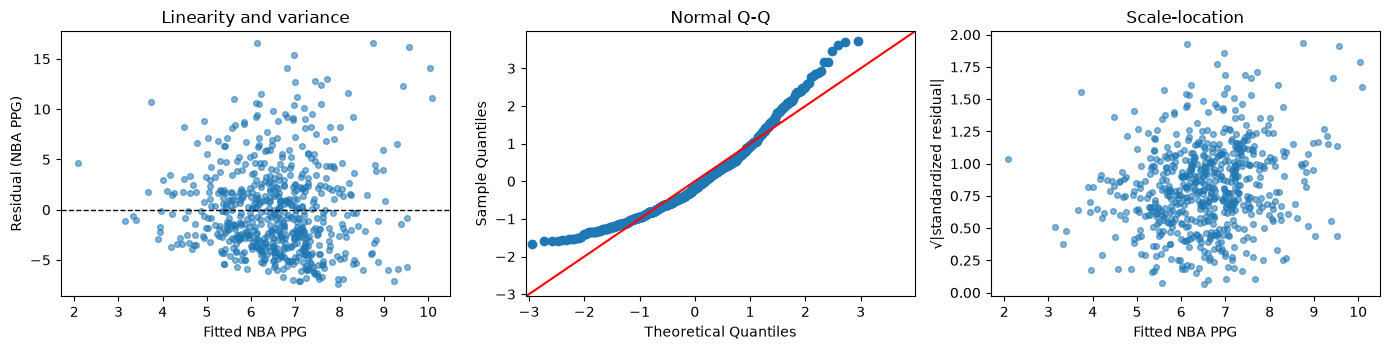

VIF (course guideline < 5):


,variable,VIF
0,"C(position_group, Treatment(reference=""Guard"")...",1.806452
1,"C(position_group, Treatment(reference=""Guard"")...",1.894608
2,ncaa_ppg,1.161712
3,ncaa_apg,1.724717
4,ncaa_fg_pct,1.480099


Independence: one row per unique player; cohort-level correlations remain possible.
If a serious issue appears, set FIX_FORMULA below and explain the change in slides.


In [3]:
# Fit on training data only. If needed, edit FIX_FORMULA based on these diagnostics, then rerun.
initial=smf.ols(FORMULA, data=train).fit()
print(initial.summary().tables[1])

def diagnostics(fit,label):
    residual=fit.resid
    fitted=fit.fittedvalues
    scale = 'log(1 + NBA PPG)' if label == 'log_transformed' else 'NBA PPG'
    fig,axs=plt.subplots(1,3,figsize=(14,3.6))
    axs[0].scatter(fitted,residual,alpha=.55,s=17)
    axs[0].axhline(0,color='black',linestyle='--',linewidth=1)
    axs[0].set(xlabel=f'Fitted {scale}',ylabel=f'Residual ({scale})',title='Linearity and variance')
    sm.qqplot(residual,line='45',fit=True,ax=axs[1]);axs[1].set(title='Normal Q-Q')
    standardized_residuals = fit.get_influence().resid_studentized_internal
    axs[2].scatter(fitted, np.sqrt(np.abs(standardized_residuals)), alpha=.55, s=17)
    axs[2].set(xlabel=f'Fitted {scale}',ylabel='√|standardized residual|',title='Scale-location')
    fig.tight_layout()
    fig.savefig(REPORT/f'{MODEL}_{label}_diagnostics.png',dpi=160)
    plt.show()
    design=pd.DataFrame(fit.model.exog,columns=fit.model.exog_names)
    vif=pd.DataFrame([{'variable':col,'VIF':variance_inflation_factor(design.to_numpy(),i)}
            for i,col in enumerate(design.columns) if col!='Intercept'])
    print('VIF (course guideline < 5):')
    display(vif)
    return vif

initial_vif=diagnostics(initial,'initial')
print('Independence: one row per unique player; cohort-level correlations remain possible.')
print('If a serious issue appears, set FIX_FORMULA below and explain the change in slides.')

In [4]:
# OPTIONAL FIX. Keep None unless justified by an actual training residual or VIF diagnostic.
# Example for Member 1: remove height if highly collinear with wingspan.
FIX_FORMULA=None
final=initial if FIX_FORMULA is None else smf.ols(FIX_FORMULA,data=train).fit()
if FIX_FORMULA is not None:
    final_vif=diagnostics(final,'fixed')
else:
    final_vif=initial_vif

# Holdout evaluation once, using the common split (seed 42, stratified by position).
pred=final.predict(test)
mse=mean_squared_error(test.ppg_3yr,pred)
r2=r2_score(test.ppg_3yr,pred)
print(f'\nTEST MSE: {mse:.3f} PPG² | TEST R²: {r2:.3f}')
print('Final equation:',final.model.formula)
coef=pd.DataFrame({'term':final.params.index,'estimate':final.params.values,
                   'p_value':final.pvalues.values})
display(coef)
coef.to_csv(REPORT/f'{MODEL}_coefficients.csv',index=False)
summary=pd.DataFrame([{'model':MODEL,'train_n':len(train),'test_n':len(test),
                       'test_mse':mse,'test_r2':r2,
                       'formula':final.model.formula,
                       'max_vif':final_vif.VIF.max()}])
summary.to_csv(REPORT/f'{MODEL}_metrics.csv',index=False)
print('Saved metrics, coefficients, and diagnostic figure(s) to reports/.')


TEST MSE: 17.405 PPG² | TEST R²: 0.074
Final equation: ppg_3yr ~ ncaa_ppg + ncaa_apg + ncaa_fg_pct + C(position_group, Treatment(reference="Guard"))


,term,estimate,p_value
0,Intercept,-1.004984,0.566709
1,"C(position_group, Treatment(reference=""Guard"")...",-0.348123,0.674967
2,"C(position_group, Treatment(reference=""Guard"")...",-0.140594,0.778646
3,ncaa_ppg,0.243965,0.000001
4,ncaa_apg,0.153651,0.275831
5,ncaa_fg_pct,0.071799,0.034790


Saved metrics, coefficients, and diagnostic figure(s) to reports/.


### Fitted NCAA Regression Equation

$$
\widehat{\text{NBA PPG}} = -1.005 + 0.244(\text{NCAA PPG}) + 0.154(\text{NCAA APG}) + 0.0718(\text{NCAA FG\%}) - 0.141(\text{Forward}) - 0.348(\text{Center})
$$

Quantitative interpretation: Holding NCAA APG, NCAA FG%, and position constant, each additional NCAA point per game is associated with an estimated 0.244 additional NBA points per game.

Qualitative interpretation: Holding the quantitative predictors constant, Centers are predicted to score 0.348 fewer NBA points per game than Guards, the baseline category. This difference is not statistically significant (p = 0.675).

### Regression Assumption Checks:

1. Linearity: The residuals-versus-fitted plot shows some structure, suggesting that the linearity assumption may not be fully satisfied.

2. Constant variance: The residual spread is somewhat uneven across fitted values, suggesting possible heteroscedasticity.

3. Normality: The Q-Q plot shows substantial deviations from the reference line, particularly in the tails, indicating non-normal residuals.

4. Independence: Each observation represents a unique NBA player, supporting independence. However, players from similar cohorts may still have correlated errors.

5. Multicollinearity: All variance inflation factors are below 2, well under the course guideline of 5. There is no evidence of problematic multicollinearity in the original model.

In [5]:
train["log_ppg"] = np.log1p(train["ppg_3yr"])

print("Transformed outcome created successfully")

Transformed outcome created successfully


In [6]:
LOG_FORMULA = 'log_ppg ~ ncaa_ppg + ncaa_apg + ncaa_fg_pct + C(position_group, Treatment(reference="Guard"))'

log_model = smf.ols(LOG_FORMULA, data=train).fit()

print(log_model.summary())

                            OLS Regression Results                            
Dep. Variable:                log_ppg   R-squared:                       0.042
Model:                            OLS   Adj. R-squared:                  0.035
Method:                 Least Squares   F-statistic:                     5.411
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           7.02e-05
Time:                        18:02:11   Log-Likelihood:                -581.77
No. Observations:                 616   AIC:                             1176.
Df Residuals:                     610   BIC:                             1202.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                                                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------

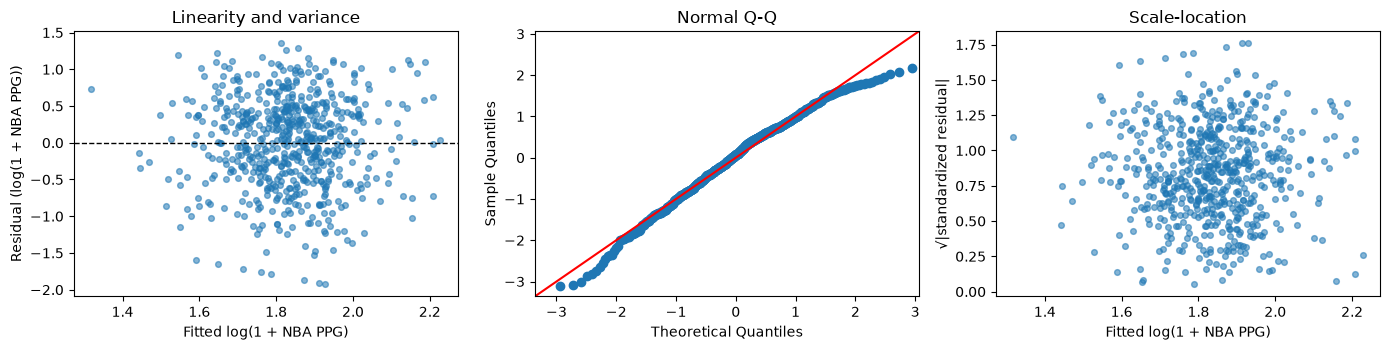

VIF (course guideline < 5):


,variable,VIF
0,"C(position_group, Treatment(reference=""Guard"")...",1.806452
1,"C(position_group, Treatment(reference=""Guard"")...",1.894608
2,ncaa_ppg,1.161712
3,ncaa_apg,1.724717
4,ncaa_fg_pct,1.480099


In [7]:
log_vif = diagnostics(log_model, "log_transformed")

In [8]:
# Predict on the log(1 + PPG) scale
log_predictions = log_model.predict(test)

# Convert predictions back to NBA PPG
ppg_predictions = np.expm1(log_predictions)

# Evaluate on the original NBA PPG scale
log_mse = mean_squared_error(test["ppg_3yr"], ppg_predictions)
log_r2 = r2_score(test["ppg_3yr"], ppg_predictions)

print(f"Log model TEST MSE: {log_mse:.3f}")
print(f"Log model TEST R²: {log_r2:.3f}")

Log model TEST MSE: 18.864
Log model TEST R²: -0.003


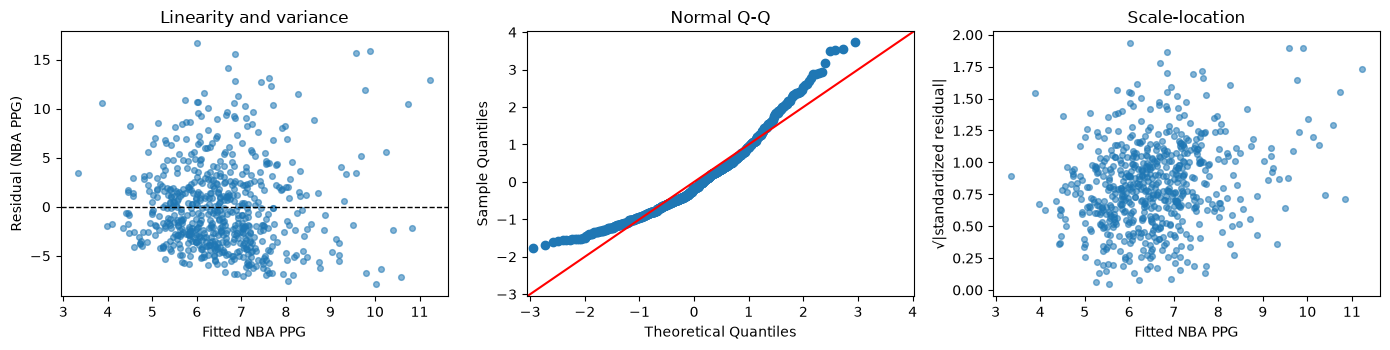

VIF (course guideline < 5):


,variable,VIF
0,"C(position_group, Treatment(reference=""Guard"")...",1.828783
1,"C(position_group, Treatment(reference=""Guard"")...",1.895489
2,ncaa_ppg,25.962022
3,I(ncaa_ppg ** 2),25.373629
4,ncaa_apg,1.725404
5,ncaa_fg_pct,1.480164


In [9]:
# Attempted fix: quadratic NCAA PPG term
QUAD_FORMULA = (
    'ppg_3yr ~ ncaa_ppg + I(ncaa_ppg**2) + ncaa_apg '
    '+ ncaa_fg_pct + '
    'C(position_group, Treatment(reference="Guard"))'
)

quad_model = smf.ols(QUAD_FORMULA, data=train).fit()

quad_vif = diagnostics(quad_model, 'quadratic')

### Attempted Fixes and Final Model Selection

The original regression showed departures from residual normality and possible non-constant variance.

I attempted a log(1 + NBA PPG) transformation to improve the residual distribution while accommodating players with zero PPG. The transformed model produced a Q-Q plot closer to the reference line, although deviations remained in the tails.

I also explored adding a quadratic NCAA PPG term to address possible nonlinearity. However, this introduced substantial multicollinearity, with VIF values around 25 for the linear and quadratic NCAA PPG terms.

I retained the original model because it was simpler, had low VIF values, and avoided the additional multicollinearity introduced by the quadratic model. Although the log transformation improved residual normality, it did not fully resolve the assumption violations.

For reference, the original model achieved a test MSE of 17.405 and test R² of 0.074, compared with 18.864 and -0.003 for the log-transformed model after converting predictions back to NBA PPG. These results suggest limited predictive performance for both models. Comparing experimental models on the test set is a limitation because the test set should ideally be reserved for final evaluation.